In [64]:
import numpy as np
from scipy.fft import dct, idct

In [65]:
# 1. 신호 데이터 만들기
x = np.linspace(0, 10, 20)
signal = np.cos(x)
signal

array([ 1.        ,  0.8646637 ,  0.49528663, -0.00815095, -0.5093823 ,
       -0.87273782, -0.99986712, -0.8563598 , -0.48105935,  0.02445069,
        0.52334259,  0.88058   ,  0.99946853,  0.84782832,  0.46670422,
       -0.04074393, -0.53716381, -0.88818817, -0.99880433, -0.83907153])

In [66]:
# 2. DCT 변환 (Type 2가 기본값)
coef = dct(signal)
coef

array([-1.85840882,  4.2314536 , -2.87539727, 19.27488292,  4.29855415,
       -3.06196622,  0.80937033, -1.08415645,  0.36619672, -0.56065306,
        0.2056806 , -0.33212338,  0.12595757, -0.20690773,  0.07861428,
       -0.12713732,  0.04643712, -0.06943283,  0.02166901, -0.02211782])

In [67]:
# 3. IDCT 역변환
reconstructed = idct(coef)
reconstructed

array([ 1.        ,  0.8646637 ,  0.49528663, -0.00815095, -0.5093823 ,
       -0.87273782, -0.99986712, -0.8563598 , -0.48105935,  0.02445069,
        0.52334259,  0.88058   ,  0.99946853,  0.84782832,  0.46670422,
       -0.04074393, -0.53716381, -0.88818817, -0.99880433, -0.83907153])

In [68]:
np.sum((signal - reconstructed) ** 2)

np.float64(4.9897233740427555e-31)

In [69]:
from os import getcwd

getcwd()

'c:\\Users\\user\\source\\repos\\project durumari\\tests'

In [70]:
f = open("./aes.py", "rb")

In [71]:
from struct import unpack

fr = f.read(0x100)

In [72]:
l = unpack("<" + "B" * len(fr), fr)

In [73]:
IS_NORM = "ortho"  # None

In [74]:
coef = np.round(dct(l, norm=IS_NORM)).astype(np.int64)
coef

array([1335,   54,  -49,  -60,    1,  -69,  -93,  -14,   24,  -60,  -52,
        -94,  -25,  -40,  111,  -80,  -20,   21,   -8,    7,   16,   27,
        -67,   21,    0,   59,   55,  -36,  -26,   21,   21,   -6,  -63,
         21, -123,  -37,  121,  -13,   30,  -28,   62,   23,   14,  -66,
        -70,  -25,   24,  -40,   29,  -23,  -64,   89,   -9,  -24,   -1,
       -100,  -34,   26,   11,    7,   55,  -29,   30,   13,  -32,  -21,
          3,  -21,   27,  -22,  -26,   29,   23,  -18,  -33,  -25,   34,
        -36,  -72,    5,   27,   17,   17,   33,  -16,  -35,   -3,   -2,
        -21,   31,   -4,   20,   42,   37,   24,    9,   30,  -55,    7,
         16,   39,  -68,    7,  -28,  -14,  -16,   25,   21,  -13,   -3,
         -6,   12,  -62,   11,   52,   42,   -9,    8,   11,  -16,  -39,
        -10,   39,    6,   67,   -1,   46,   32,  -28,  -23,   27,   -3,
        -15,  -33,  -19,  -21,    1,   24,  -23,  -51,    2,   66,    9,
          3,  -12,   27,    2,  -20,  -26,   15,  -

In [75]:
coef = np.array([i if abs(i) > 99 else 0 for i in coef])
coef

array([1335,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,  111,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0, -123,    0,  121,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
       -100,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    0,    0,   

In [76]:
reconstructed = np.round(idct(coef, norm=IS_NORM)).astype(np.int64)
reconstructed

array([ 85,  88,  93,  97,  98,  96,  90,  83,  78,  76,  78,  82,  85,
        87,  84,  78,  70,  63,  60,  62,  69,  77,  85,  90,  90,  87,
        83,  80,  79,  82,  86,  90,  91,  91,  88,  86,  85,  88,  94,
       101, 107, 107, 103,  93,  81,  70,  63,  62,  66,  73,  81,  86,
        87,  85,  81,  78,  76,  76,  77,  77,  76,  72,  68,  66,  68,
        75,  87, 100, 111, 116, 115, 107,  96,  84,  75,  71,  73,  78,
        84,  89,  92,  92,  91,  91,  90,  90,  89,  85,  78,  68,  57,
        50,  48,  53,  65,  80,  94, 105, 108, 104,  96,  85,  77,  72,
        72,  75,  80,  84,  88,  91,  94,  99, 104, 109, 112, 109, 101,
        88,  73,  59,  51,  51,  58,  70,  83,  94,  99,  98,  92,  84,
        76,  71,  68,  67,  67,  68,  68,  70,  75,  83,  94, 106, 116,
       119, 116, 106,  92,  78,  67,  63,  66,  75,  85,  95, 100, 101,
        97,  92,  87,  83,  79,  75,  70,  64,  58,  54,  54,  60,  71,
        84,  97, 106, 108, 103,  93,  82,  72,  68,  70,  76,  8

In [77]:
l - reconstructed

array([-51, -54, -59, -32, -29, -13, -45, -33, -25, -22, -33, -11, -18,
       -10, -52,  24,  35,  45,  41, -30,  32,  33,  14,  24,  31,  25,
        33,  25,  32,  28, -54,   7,  19,   9, -56,  14,  16,  11,  20,
        20,   5,   9,   2,  18,  29, -24, -53, -52,   7,  37,  34,  30,
        10,  23,  27, -46,  40,  28,  24, -45,  35,  38,  40,  55, -36,
        26,  33,  16, -10,  -2,  -5, -10,  12, -52,  25,  30,  39,  23,
        26,  11,   9,  18,   8,  30, -58,  29,  16,  31,  26, -10,   1,
       -40, -38, -21, -33, -48, -62,   7,  13,  12,   8,  26,  33, -40,
       -27,  34, -48,  28,  17,  21, -62,   6,   6,   6,   4, -12,   7,
        20, -41,  40,  63,  70,  54,  46,  28,   9,  15,  -1,  20,  20,
        45, -61, -58,  17,  37,  33, -36,  31,  35,  16,  20,  15,  -4,
        -3, -15,  -6, -60,  24,  38,  45,  35, -43,  17,  16,  14,   8,
         0,  24, -55,  22,  36, -17, -12, -54, -48, -22, -22, -28, -39,
        25,   0,  -3,  -3,  -4, -61, -42, -16, -36,  28,  45,  3

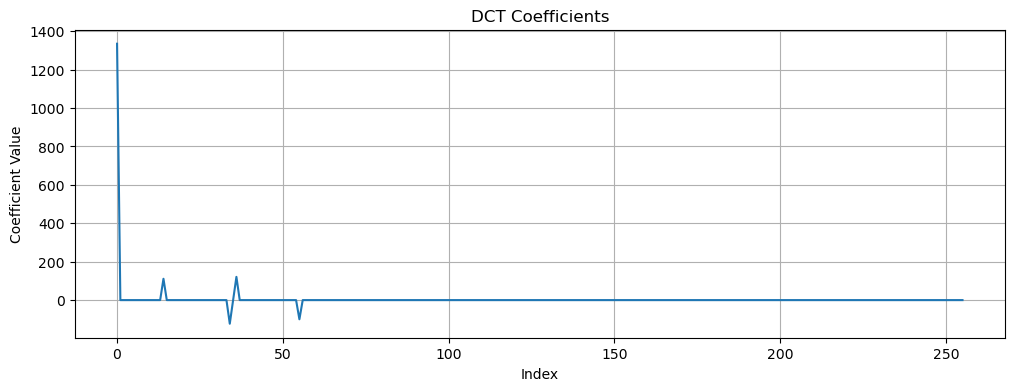

In [78]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.plot(coef)
plt.xlabel("Index")
plt.ylabel("Coefficient Value")
plt.title("DCT Coefficients")
plt.grid(True)
plt.show()